<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Source-Code Structure Analysis](https://github.com/Query-farm/vgi-code)

Detect languages, count lines and functions, and extract symbols, imports and comments from source code.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-code/blob/main/notebooks/02_import_syntax_and_text_decoys.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-code/blob/main/notebooks/README.md)

## 02 · Import syntax is more precise than an import-shaped line

**Which mentions of an import are actually Python import statements?** We compare
a plain substring scan with the worker's syntax-aware extraction, then inspect the
comments and string literals that explain the difference.

This is one authored module, held as SQL text and never executed. An import statement
records syntax, not whether a branch runs, a package is installed, or a dependency
is used. All comparisons are limited to this small fixture.

### Choose whether to keep the decoys

`INCLUDE_DECOYS=True` appends one comment and one string literal containing
import-shaped text. Set it to `False` for the experiment; the two real import
statements stay exactly the same.

In [1]:
INCLUDE_DECOYS = True

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.10":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.10"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display

check_runtime()
prepare("code")
import code_example as example  # noqa: E402

session = connect(globals())
theme()
if type(INCLUDE_DECOYS) is not bool:
    raise ValueError("INCLUDE_DECOYS must be True or False.")

### Attach the released worker

The literal `github-auto` location downloads and verifies the native release.
Analysis runs locally through VGI; no module is imported or executed.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'code' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-code@v0.4.0');

,Success


### Keep the text and its extracted categories together

The original source has two import statements. The optional comment names `secrets`,
and a string literal contains `import socket`; neither adds an import statement.
The worker returns complete statement/comment/string text, so retain that evidence
before reducing it to counts.

In [5]:
%%sql
CREATE TABLE source_text AS
SELECT 'imports.py' AS filename, $$import math
from pathlib import Path
$$ || CASE WHEN {{ INCLUDE_DECOYS }} THEN $$# import secrets is only a comment
LABEL = "import socket"
$$ ELSE '' END AS source;
CREATE TABLE extracted AS
SELECT *, code.main.extract_imports(source,'python') AS imports,
 code.main.extract_comments(source,'python') AS comments,
 code.main.extract_strings(source,'python') AS strings FROM source_text;
SELECT filename,source,imports,comments,strings FROM extracted;

,filename,source,imports,comments,strings
0,imports.py,import math\nfrom pathlib import Path\n# impor...,"[import math, from pathlib import Path]",[# import secrets is only a comment],"[""import socket""]"


### Separate text matching from syntax

Here, each real import statement occupies one line, so line and statement counts
can be compared directly. That assumption would fail for multiline statements.
The simple text scan also finds the optional comment and string. The extracted
categories show where those two extra matches came from.

In [6]:
%%sql counts <<
WITH lines AS (SELECT unnest(string_split(source,chr(10))) AS line FROM source_text),
 measures AS (
 SELECT 1 AS position,'Lines containing import text' AS measure,count(*) AS observed
 FROM lines WHERE contains(line,'import ')
 UNION ALL SELECT 2,'Parsed import statements',len(imports) FROM extracted
 UNION ALL SELECT 3,'Parsed comments',len(comments) FROM extracted
 UNION ALL SELECT 4,'Parsed string literals',len(strings) FROM extracted)
SELECT measure,observed FROM measures ORDER BY position;

,measure,observed
0,Lines containing import text,4
1,Parsed import statements,2
2,Parsed comments,1
3,Parsed string literals,1


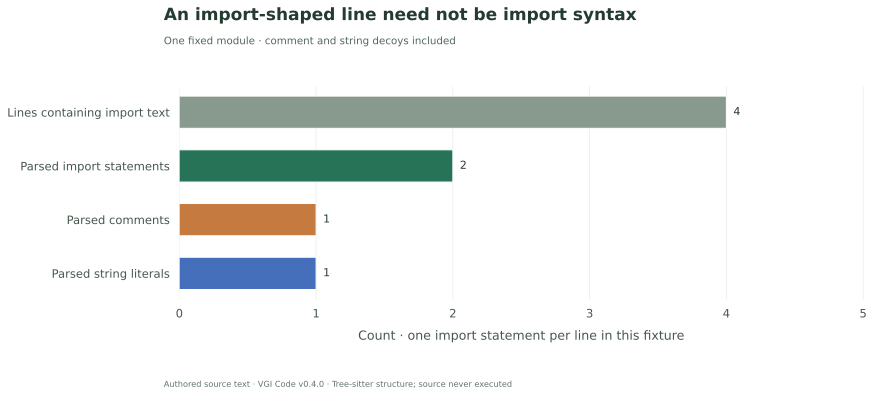

The substring scan finds **4 lines**, while the parser returns **2 import statements**. Removing the comment and string changes the text-match count, but preserves both actual import statements. This does not establish which imports execute or are needed.

In [7]:
counts = globals()["counts"]
display(counts)
example.plot_imports(counts, INCLUDE_DECOYS)
prose(
    f"The substring scan finds **{int(counts.iloc[0].observed)} lines**, while the parser returns "
    f"**{int(counts.iloc[1].observed)} import statements**. Removing the comment and string "
    "changes the text-match count, but preserves both actual import statements. This does not establish which imports execute or are needed."
)

### Inspect actual statements before interpreting dependencies

We keep `import math` and `from pathlib import Path` as statements. Turning a
statement into a dependency inventory would need more analysis of aliases,
relative imports and control flow. Comments and strings remain useful source data,
but should not silently join the import inventory.

In [8]:
%%sql
SELECT 'import' AS category,unnest(imports) AS extracted_text FROM extracted
UNION ALL SELECT 'comment',unnest(comments) FROM extracted
UNION ALL SELECT 'string',unnest(strings) FROM extracted;

,category,extracted_text
0,import,import math
1,import,from pathlib import Path
2,comment,# import secrets is only a comment
3,string,"""import socket"""


### Check the controlled comparison

These checks protect the fixture's interpretation, including missing inputs.
They do not establish that extraction is a complete runtime dependency analysis.

In [9]:
%%sql checks <<
SELECT 'Both real statements retained exactly' AS check_name,
 imports=['import math','from pathlib import Path'] AS passed FROM extracted
UNION ALL SELECT 'Comment retained only when requested',
 len(comments)=CASE WHEN {{ INCLUDE_DECOYS }} THEN 1 ELSE 0 END FROM extracted
UNION ALL SELECT 'String retained only when requested',
 len(strings)=CASE WHEN {{ INCLUDE_DECOYS }} THEN 1 ELSE 0 END FROM extracted
UNION ALL SELECT 'Text scan agrees with the one-line fixture accounting',
 (SELECT count(*) FROM (SELECT unnest(string_split(source,chr(10))) AS line FROM source_text)
 WHERE contains(line,'import '))=len(imports)+len(comments)+len(strings) FROM extracted
UNION ALL SELECT 'NULL source is unknown, not an empty parsed inventory',
 code.main.extract_imports(NULL,'python') IS NULL
 AND code.main.extract_comments(NULL,'python') IS NULL
 AND code.main.extract_strings(NULL,'python') IS NULL;

In [10]:
checks = globals()["checks"]
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"All **{len(checks)} fixture checks** passed. The two real imports remain intact; absent source stays unknown."
)

,check_name,passed
0,Both real statements retained exactly,True
1,Comment retained only when requested,True
2,String retained only when requested,True
3,Text scan agrees with the one-line fixture acc...,True
4,"NULL source is unknown, not an empty parsed in...",True


All **5 fixture checks** passed. The two real imports remain intact; absent source stays unknown.

### Experiment · remove the decoys

Set `INCLUDE_DECOYS=False`, restart and run all. Predict which returned categories
become empty and which two statements remain. The substring count drops from four
to two, while the parsed import count remains two. Restore `True` for the saved default.

```sh
uv run --locked vgi-notebooks 02_import_syntax_and_text_decoys.ipynb \
  --parameters '{"INCLUDE_DECOYS":false}' --output-dir artifacts/no-decoys
```

In [11]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-code](https://github.com/Query-farm/vgi-code)
